<a href="https://colab.research.google.com/github/iRosses-omics/ageing-clock-disagreement/blob/main/clock_trust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# When can we trust an ageing clock?
Six published epigenetic clocks often give different ages for the same person. This notebook asks whether that **disagreement** flags unreliable estimates, and whether it can be used to build prediction intervals that are reliable **for everyone**, not only on average.

Two independent whole-blood 450k cohorts:
- **GSE40279** (Hannum et al.), n = 656
- **GSE87571** (Johansson et al.), n = 729

Run all cells in order (each dataset is ~1–3 GB and is read in chunks).

In [1]:
!pip -q install biolearn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Setup

In [2]:
import gzip, gc, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from biolearn.data_library import GeoData
from biolearn.model_gallery import ModelGallery

CLOCKS = ["Horvathv1", "Hannum", "PhenoAge", "Horvathv2", "Lin", "Zhang_10"]
TARGET = "Horvathv1"          # clock used for the prediction intervals
gallery = ModelGallery()

def wget(url):
    os.system(f'wget -q -c --tries=10 --user-agent="Mozilla/5.0" "{url}"')

def read_meta(path):
    rows, start = {}, None
    with gzip.open(path, "rt") as f:
        for i, line in enumerate(f):
            if line.startswith("!Sample_"):
                key, *vals = line.rstrip("\n").split("\t")
                rows.setdefault(key, []).append([v.strip('"') for v in vals])
            if line.startswith("!series_matrix_table_begin"):
                start = i + 1; break
    meta = pd.DataFrame(index=rows["!Sample_geo_accession"][0])
    for vals in rows["!Sample_characteristics_ch1"]:
        k = vals[0].split(":")[0].strip().lower()
        meta[k] = [v.split(":", 1)[1].strip() if ":" in v else None for v in vals]
    agecol = [c for c in meta.columns if c.startswith("age")][0]
    meta["age"] = pd.to_numeric(meta[agecol], errors="coerce")
    for c in ["gender", "sex"]:
        if c in meta.columns: meta["sex"] = meta[c]
    titles = [t.split()[0] for t in rows["!Sample_title"][0]]
    return meta, start, titles

def run_clocks(meta, dnam):
    data = GeoData(meta, dnam); preds = {}
    for name in CLOCKS:
        try: preds[name] = gallery.get(name).predict(data)["Predicted"]
        except Exception as e: print("skip", name, e)
    return meta.join(pd.DataFrame(preds), how="inner")

def age_acceleration(df):
    age = df["age"].astype(float); acc = pd.DataFrame(index=df.index)
    for c in [c for c in CLOCKS if c in df.columns]:
        b, a = np.polyfit(age, df[c], 1); r = df[c] - (b * age + a)
        acc[c] = (r - r.mean()) / r.std()
    return acc

def evaluate(df, name, n_splits=20):
    age = df["age"].astype(float); acc = age_acceleration(df); d = acc.std(axis=1)
    lvl = lambda n: min(1.0, np.ceil((n + 1) * 0.9) / n)
    out = []
    for seed in range(n_splits):
        idx = np.random.default_rng(seed).permutation(df.index); h = len(idx) // 2
        cal, test = idx[:h], idx[h:]
        b, a = np.polyfit(age[cal], df.loc[cal, TARGET], 1)
        err = ((df[TARGET] - a) / b - age).abs()
        cut = d[cal].quantile(.8)                       # group boundary from calibration half only
        hc, ht = d[cal] > cut, d[test] > cut
        q = np.quantile(err[cal], lvl(h))                # standard: one width for everyone
        q_lo = np.quantile(err[cal][~hc], lvl((~hc).sum()))   # disagreement-aware (Mondrian)
        q_hi = np.quantile(err[cal][hc], lvl(hc.sum()))
        out.append({
            "median_error_agree": err[test][~ht].median(), "median_error_disagree": err[test][ht].median(),
            "standard_cov_agree": (err[test][~ht] <= q).mean(), "standard_cov_disagree": (err[test][ht] <= q).mean(),
            "aware_cov_agree": (err[test][~ht] <= q_lo).mean(), "aware_cov_disagree": (err[test][ht] <= q_hi).mean(),
            "standard_width": 2 * q, "aware_width_agree": 2 * q_lo, "aware_width_disagree": 2 * q_hi,
            "spearman_rho": d[test].corr(err[test], method="spearman")})
    r = pd.DataFrame(out).mean()
    cc = acc.corr().values[np.triu_indices(acc.shape[1], 1)]
    r["clock_corr_min"], r["clock_corr_max"], r["n"] = cc.min(), cc.max(), len(df)
    r.name = name
    return r, d

## Cohort 1 – GSE40279 (data inside the series matrix)

In [3]:
wget("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/matrix/GSE40279_series_matrix.txt.gz")
path = "GSE40279_series_matrix.txt.gz"
meta1, start, _ = read_meta(path)
header = pd.read_csv(path, sep="\t", skiprows=start, nrows=0).columns
parts = [ch for ch in pd.read_csv(path, sep="\t", skiprows=start, index_col=0,
         dtype={c: "float32" for c in header[1:]}, na_values=["null", ""], chunksize=50000, comment="!")]
dnam = pd.concat(parts); del parts
dnam.index = dnam.index.str.strip('"'); dnam.columns = dnam.columns.str.strip('"')
print("GSE40279 people:", len(meta1), "| CpGs:", dnam.shape[0])
df1 = run_clocks(meta1, dnam); del dnam; gc.collect()

GSE40279 people: 656 | CpGs: 473034


54

## Cohort 2 – GSE87571 (data in two supplementary files)
Each sample has two columns (`Xn`, `Xn.1`); the beta value is in `Xn`, or in `Xn.1` when `Xn` is empty. A chrY probe is used as a sanity check.

In [4]:
base = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE87nnn/GSE87571/"
wget(base + "matrix/GSE87571_series_matrix.txt.gz")
for f in ["GSE87571_matrix1of2.txt.gz", "GSE87571_matrix2of2.txt.gz"]: wget(base + "suppl/" + f)

meta2, _, xid = read_meta("GSE87571_series_matrix.txt.gz")
x2gsm = dict(zip(xid, meta2.index))

def read_part(path):
    header = pd.read_csv(path, sep="\t", nrows=0).columns
    samples = [c for c in header[1:] if not c.endswith(".1")]
    out = []
    for ch in pd.read_csv(path, sep="\t", index_col=0, na_values=["NA"],
                          dtype={c: "float32" for c in header[1:]}, chunksize=50000):
        out.append(pd.DataFrame({s: ch[s].fillna(ch[s + ".1"]) if s + ".1" in ch else ch[s]
                                 for s in samples}).astype("float32"))
    return pd.concat(out)

dnam = pd.concat([read_part("GSE87571_matrix1of2.txt.gz"), read_part("GSE87571_matrix2of2.txt.gz")], axis=1)
dnam = dnam.rename(columns=x2gsm)
keep = [g for g in meta2.index if g in dnam.columns and pd.notna(meta2.loc[g, "age"])]
meta2, dnam = meta2.loc[keep], dnam[keep]
print("GSE87571 people:", len(meta2), "| CpGs:", dnam.shape[0])
print(pd.DataFrame({"sex": meta2["sex"], "chrY probe cg00050873": dnam.loc["cg00050873"]}).groupby("sex").median())
df2 = run_clocks(meta2, dnam); del dnam; gc.collect()

GSE87571 people: 729 | CpGs: 485512
        chrY probe cg00050873
sex                          
Female               0.163123
Male                 0.842790


0

## Results

In [5]:
r1, d1 = evaluate(df1, "GSE40279")
r2, d2 = evaluate(df2, "GSE87571")
res = pd.concat([r1, r2], axis=1)
print(res.round(3))

for name, df, d in [("GSE40279", df1, d1), ("GSE87571", df2, d2)]:
    g = pd.cut(df["age"].astype(float), [0, 40, 60, 80, 120], labels=["<40", "40-60", "60-80", "80+"])
    print(f"\n{name}: median disagreement by age group"); print(d.groupby(g, observed=True).median().round(2))

                       GSE40279  GSE87571
median_error_agree        3.461     2.996
median_error_disagree     5.188     4.754
standard_cov_agree        0.928     0.941
standard_cov_disagree     0.776     0.753
aware_cov_agree           0.893     0.897
aware_cov_disagree        0.892     0.913
standard_width           19.427    17.210
aware_width_agree        17.565    14.583
aware_width_disagree     29.272    24.978
spearman_rho              0.196     0.179
clock_corr_min            0.159     0.118
clock_corr_max            0.630     0.621
n                       656.000   729.000

GSE40279: median disagreement by age group
age
<40      0.56
40-60    0.61
60-80    0.62
80+      0.74
dtype: float64

GSE87571: median disagreement by age group
age
<40      0.59
40-60    0.67
60-80    0.72
80+      0.90
dtype: float64


## Main figure

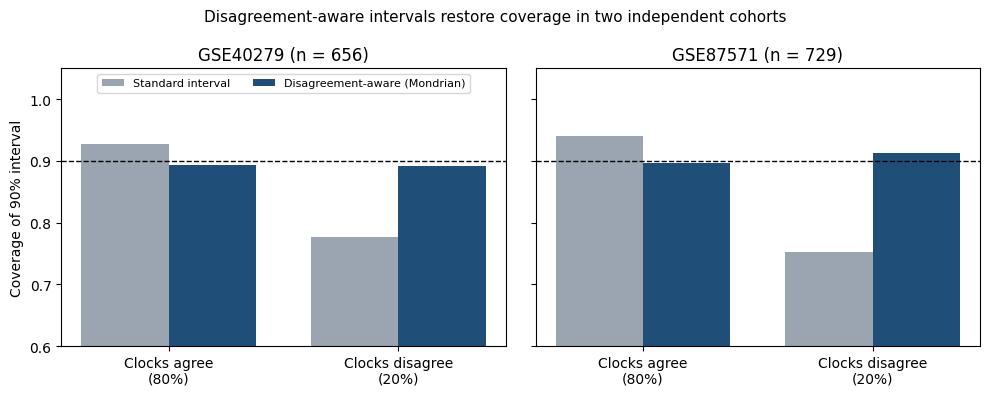

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (gse, r) in zip(axes, [("GSE40279", r1), ("GSE87571", r2)]):
    x = np.arange(2); w = 0.38
    ax.bar(x - w/2, [r["standard_cov_agree"], r["standard_cov_disagree"]], w, label="Standard interval", color="#9aa5b1")
    ax.bar(x + w/2, [r["aware_cov_agree"], r["aware_cov_disagree"]], w, label="Disagreement-aware (Mondrian)", color="#1f4e79")
    ax.axhline(.9, ls="--", c="k", lw=1); ax.set_ylim(.6, 1.05)
    ax.set_xticks(x); ax.set_xticklabels(["Clocks agree\n(80%)", "Clocks disagree\n(20%)"])
    ax.set_title(f"{gse} (n = {int(r['n'])})")
axes[0].set_ylabel("Coverage of 90% interval"); axes[0].legend(loc="upper center", fontsize=8, ncol=2)
fig.suptitle("Disagreement-aware intervals restore coverage in two independent cohorts", fontsize=11)
plt.tight_layout(); plt.savefig("main_figure.png", dpi=200); plt.show()

## Limitations
- Two cohorts, one tissue (blood), cross-sectional; no health outcomes.
- The Hannum clock was trained on GSE40279.
- The disagreement–error link is real but modest (Spearman ρ ≈ 0.2); the gain is in fair, honest uncertainty, not in precision.
- Uncertainty for clocks has been studied before (e.g. conformalized quantile regression, medRxiv 2024); the angle here is cross-clock disagreement as the signal.